# Inference of the held-out blocks

Do the fitted models reproduce the **temporal structure of the swimming** and not only the probability of a swim in a bin? Every model is run freely over the whole held-out block and the probability of a swim *k* seconds after a bin that is a swim (or a pause), `P(state(t+k) | state(t))`, is compared with the real block.

**What is done**
1. *Fits:* the cross-validation fits of [`01_fit_swim_oxygen_models.ipynb`](01_fit_swim_oxygen_models.ipynb) (`fits.pkl`: preprocessed inputs and the weights of every fish, fold and model). Nothing is refitted.
2. *Free run:* for every held-out block the model gets the **real** swim and oxygen history up to the first bin of the block and then generates the block by itself: in every bin a swim is drawn with `p = sigmoid(η)` (η from the weights, the model's *own* simulated past swims and the measured oxygen; the condition of each bin is given); a simulated swim gets a swim input drawn from the swim bins of the training data of the same condition. No real swim of the block is used after its first bin. 100 independent sequences per model and block.
3. *Statistics:* inside the real block and inside every simulated block, from all pairs of bins (t, t+k): the probability that bin t+k is a swim given that bin t is a swim / a pause, pooled over the blocks of a condition (and over the simulated sequences). One value per fish, condition, model and k.
4. *Comparison:* the 2 × 2 matrices (mean over the fish) and the mean absolute difference between a model's and the real matrix, tested against the Full model across the fish.

In [1]:
import os
for v in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']: os.environ[v] = '1'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, textwrap
import swim_oxygen_models as som

RESULTS_FILE = 'fits.pkl'            # written by the fitting notebook
N_JOBS = 64
HORIZON, N_SIM = 10, 100             # lags k = 1 ... HORIZON; simulated sequences per model and block
KLIST = (1, 2, 3)                    # the lags shown below
CC = {'normoxia': '#666666', 'hypoxia': '#99ccff'}
cfg, fishes, LF, LFULL = som.load_results(RESULTS_FILE)
print(len(fishes), 'fish:', [f['name'] for f in fishes])

7 fish: ['20220728-fish04', '20220730-fish01-TS2', '20221118-fish01', 'fish01-6dpf', 'fish01-7dpf-grating', 'fish03-7dpf', '20220912-fish02']


In [2]:
SIM = som.run_simulations(fishes, LF, cfg, horizon=HORIZON, n_sim=N_SIM, n_jobs=N_JOBS)      # per fish: real and simulated pair statistics
print('free runs done:', len(SIM), 'fish x', len(som.MODEL_NAMES), 'models x', cfg.n_folds, 'folds x 2 conditions,', N_SIM, 'sequences each')

free runs done: 7 fish x 5 models x 10 folds x 2 conditions, 100 sequences each


### Checks
(a) the first bin of a free run equals the model's regular one-step prediction; (b) the run does not depend on the real swims of the block after its first bin: replacing them by random numbers gives an identical run.

In [3]:
models = som.make_models(cfg)
for i in (0, 1):
    fish = fishes[i]; cond_of_bin = som.condition_of_bins(fish); tr, te, itr, ytr, ctr = som.fold_split(fish, 0); pool = som.training_pool(fish, itr, ytr, ctr)
    for ci, c in enumerate(som.CONDITIONS):
        lo, hi = int(te[c][0].min()), int(te[c][0].max())
        for nm in som.MODEL_NAMES:
            w, blocks = LF[(i, 0)][2][nm]; parts = som.model_parts(w, blocks, fish['z'])
            Y1, P1 = som.free_run(parts, fish['sw'], pool, cond_of_bin, lo, hi, 50, np.random.default_rng(5))
            sw2 = fish['sw'].copy(); sw2[lo:] = np.random.default_rng(9).random(len(sw2) - lo) * 5      # the real swims of the block (from its first bin on) replaced by noise
            Y2, P2 = som.free_run(parts, sw2, pool, cond_of_bin, lo, hi, 50, np.random.default_rng(5))
            assert np.array_equal(Y1, Y2) and np.allclose(P1, P2), ('the run depends on the real swims of the block', fish['name'], c, nm)
            eta = som.design(models[nm], fish, np.array([lo]), np.array([ci]))[0] @ w
            assert np.allclose(som.sigmoid(eta)[0], P1[:, 0], atol=1e-8), ('the first bin differs from the one-step prediction', fish['name'], c, nm)
print('checks (a) and (b) passed: 2 fish x 2 conditions x 5 models, fold 0')

checks (a) and (b) passed: 2 fish x 2 conditions x 5 models, fold 0


## Transition matrices P(state(t+k) | state(t))

Column-stochastic: rows = state of bin t+k (swim, pause), columns = state of bin t (swim, pause), so every column adds up to 1. Mean over the fish; a fish is used if it has at least 20 real pairs (t, t+k) for both states. *Data* = the real held-out blocks, models = the free-running simulations of the same blocks.

In [4]:
SRC = ['data'] + [som.LABELS[m] for m in som.MODEL_NAMES]
def mean_matrices(ci, k):
    err, use = som.transition_errors(SIM, ci, k)      # `use`: the fish with >= 20 real pairs for both states at this lag
    out = {'data': np.mean([som.transition_matrix(SIM[i]['real'], ci, k) for i in use], axis=0)}
    for m in som.MODEL_NAMES: out[som.LABELS[m]] = np.mean([som.transition_matrix(SIM[i]['model'][m], ci, k) for i in use], axis=0)
    return out, len(use)
rows, MAT = [], {}
for ci, c in enumerate(som.CONDITIONS):
    for k in KLIST:
        MAT[(c, k)], n_used = mean_matrices(ci, k)
        for s in SRC: m = MAT[(c, k)][s]; rows.append({'condition': c, 'k': k, 'source': s, 'fish': n_used, 'P(swim | swim)': m[0, 0], 'P(swim | pause)': m[0, 1]})
MAT_TABLE = pd.DataFrame(rows).set_index(['condition', 'k', 'source']).round(3)      # the matrices as a table (not displayed; type MAT_TABLE in a cell to see it)

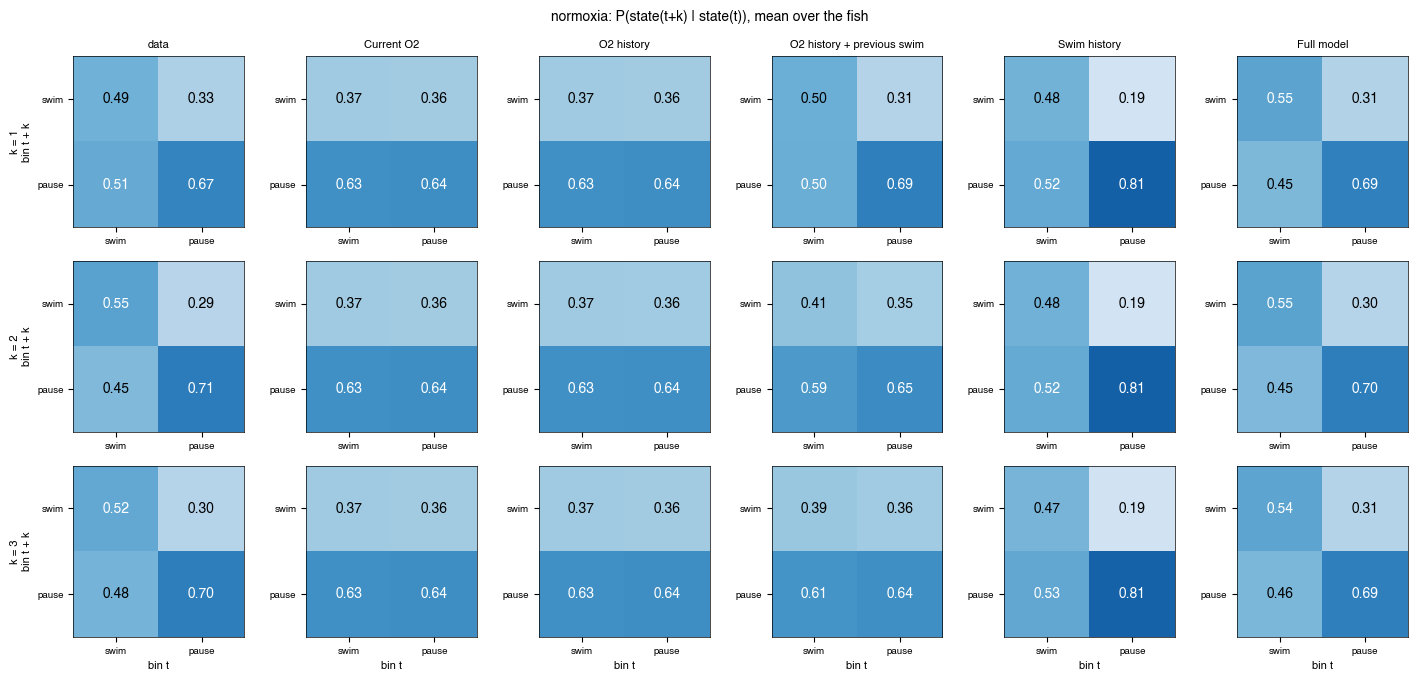

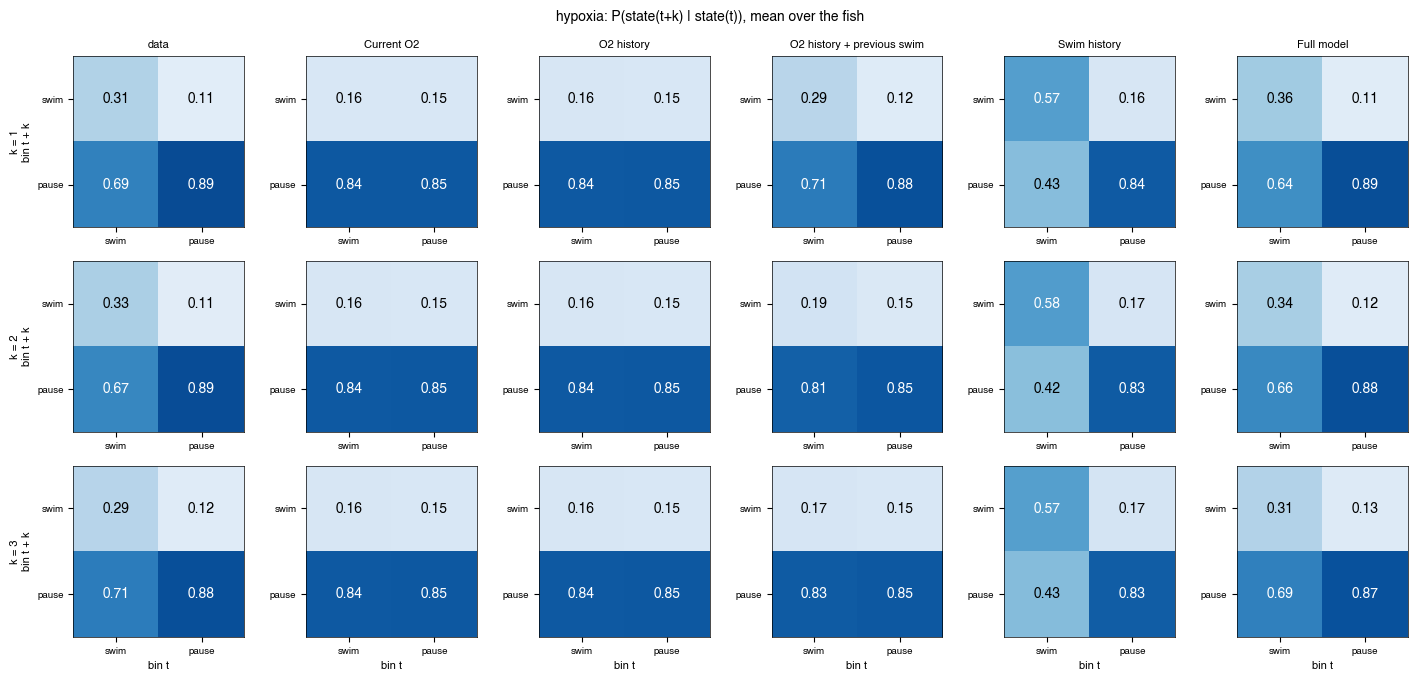

In [5]:
for c in som.CONDITIONS:
    fig, axs = plt.subplots(len(KLIST), len(SRC), figsize=(2.4 * len(SRC), 2.3 * len(KLIST)), squeeze=False)
    for r, k in enumerate(KLIST):
        for j, s in enumerate(SRC):
            ax = axs[r, j]; m = MAT[(c, k)][s]; ax.imshow(m, vmin=0, vmax=1, cmap='Blues')
            for a in range(2):
                for b in range(2): ax.text(b, a, f'{m[a, b]:.2f}', ha='center', va='center', color='white' if m[a, b] > 0.5 else 'black', fontsize=10)
            ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(['swim', 'pause'], fontsize=7); ax.set_yticklabels(['swim', 'pause'], fontsize=7)
            if r == 0: ax.set_title(s, fontsize=8)
            if j == 0: ax.set_ylabel(f'k = {k}\nbin t + k', fontsize=8)
            if r == len(KLIST) - 1: ax.set_xlabel('bin t', fontsize=8)
    fig.suptitle(f'{c}: P(state(t+k) | state(t)), mean over the fish', fontsize=10); plt.tight_layout(); plt.show()

## Error of the models

For every fish, condition and k: the mean of the four absolute differences between a model's and the real matrix entries. Bars = mean over the fish, error bars = SEM, dots = fish. Statistics, for each k, over the fish: a two-way within-subject (repeated-measures) ANOVA with the factors model (5) and oxygen condition (2) (fish = subjects); only the effect of the model is reported (with the Greenhouse-Geisser corrected p-value). Then every model is compared with the Full model with a paired t-test on the **balanced** error of each fish (the mean of its normoxia and hypoxia error, so both conditions count equally; uncorrected p-values; the Full model is not compared with itself). The statistics use the fish that have at least 20 real pairs for both states in both conditions. Stars over the two bars of a model: p of that test (\\* p < 0.05, \\*\\* p < 0.01, \\*\\*\\* p < 0.001).

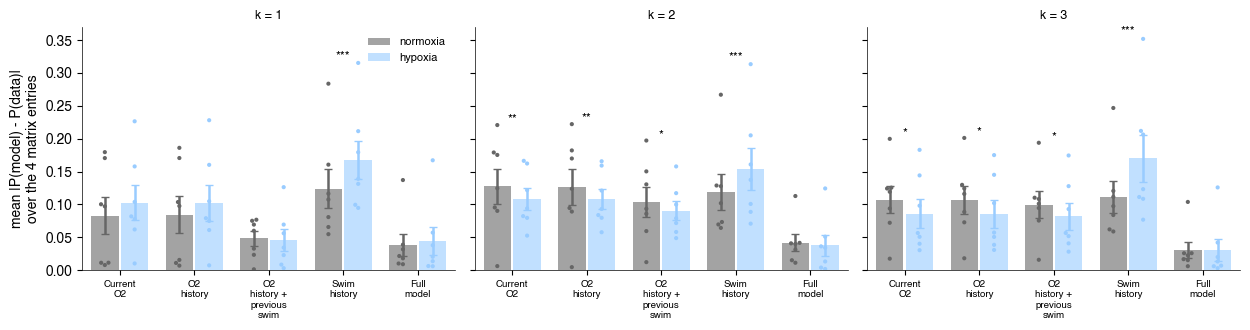

,fish,F (model),df,p (model),p (Greenhouse-Geisser)
k,,,,,
1,7,8.6310,"4, 24",0.0002,0.0070
2,7,7.6963,"4, 24",0.0004,0.0199
3,7,8.0809,"4, 24",0.0003,0.0198


fish  mean error (both conditions)  \
k model                                                            
1 Current O2                     7                        0.0926   
  O2 history                     7                        0.0932   
  O2 history + previous swim     7                        0.0470   
  Swim history                   7                        0.1456   
2 Current O2                     7                        0.1177   
  O2 history                     7                        0.1175   
  O2 history + previous swim     7                        0.0971   
  Swim history                   7                        0.1363   
3 Current O2                     7                        0.0967   
  O2 history                     7                        0.0963   
  O2 history + previous swim     7                        0.0907   
  Swim history                   7                        0.1407   

                              mean - Full model  p (paired t-test)  
k model                                                             
1 Current O2                             0.0516             0.1026  
  O2 history                             0.0523             0.1060  
  O2 history + previous swim             0.0060             0.7935  
  Swim history                           0.1047             0.0003  
2 Current O2                             0.0781             0.0073  
  O2 history                             0.0778             0.0073  
  O2 history + previous swim             0.0574             0.0384  
  Swim history                           0.0966             0.0006  
3 Current O2                             0.0659             0.0170  
  O2 history                             0.0655             0.0155  
  O2 history + previous swim             0.0599             0.0298  
  Swim history                           0.1099             0.0004

In [6]:
star = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
from IPython.display import display
fig, axs = plt.subplots(1, len(KLIST), figsize=(4.2 * len(KLIST), 3.4), sharey=True, squeeze=False); axs = axs[0]; w = 0.4; anova_rows, rows = [], []
for ax, k in zip(axs, KLIST):
    (err_n, use_n), (err_h, use_h) = (som.transition_errors(SIM, ci, k) for ci in (0, 1))
    common = [i for i in use_n if i in use_h]      # the fish with enough real pairs in both conditions (the statistics use these)
    X = np.stack([np.column_stack([err[m][[use.index(i) for i in common]] for m in som.MODEL_NAMES]) for err, use in ((err_n, use_n), (err_h, use_h))], axis=2)      # fish x models x oxygen conditions
    a = som.repeated_measures_anova_2way(X)['A']      # two-way within-subject ANOVA (model x oxygen condition): only the effect of the model is reported
    anova_rows.append({'k': k, 'fish': len(common), 'F (model)': a['F'], 'df': f"{a['df1']}, {a['df2']}", 'p (model)': a['p'], 'p (Greenhouse-Geisser)': a['p_gg']})
    pw = som.compare_with_reference(X.mean(axis=2), som.MODEL_NAMES, som.FULL_MODEL)      # balanced: the error of a fish = the mean of its two conditions; every model against the Full model (paired t-test, uncorrected)
    pts, tops = [], np.zeros(len(som.MODEL_NAMES))
    for ci, (c, err, use) in enumerate(zip(som.CONDITIONS, (err_n, err_h), (use_n, use_h))):
        x = np.arange(len(som.MODEL_NAMES)) + (ci - 0.5) * w
        mean = np.array([err[m].mean() for m in som.MODEL_NAMES]); se = np.array([err[m].std(ddof=1) / np.sqrt(len(use)) for m in som.MODEL_NAMES])
        ax.bar(x, mean, w * 0.92, color=CC[c], alpha=0.6, label=c); ax.errorbar(x, mean, se, fmt='none', ecolor=CC[c], capsize=3, elinewidth=1.8)
        pts += [{'model': m, 'condition': c, 'error': e} for m in som.MODEL_NAMES for e in err[m]]
        tops = np.maximum(tops, [max(mean[j] + se[j], err[m].max()) for j, m in enumerate(som.MODEL_NAMES)])
    for j, m in enumerate(som.MODEL_NAMES):
        if m not in pw.index: continue      # no comparison of the Full model with itself
        p = pw.loc[m, 'p (paired t-test)']
        if star(p): ax.text(j, tops[j] * 1.02, star(p), ha='center', fontsize=9)      # centred over the two bars of the model
        rows.append({'k': k, 'model': som.LABELS[m], 'fish': len(common), 'mean error (both conditions)': pw.loc[m, 'mean'], 'mean - Full model': pw.loc[m, 'mean - reference'], 'p (paired t-test)': p})
    sns.swarmplot(data=pd.DataFrame(pts), x='model', y='error', hue='condition', order=som.MODEL_NAMES, hue_order=list(som.CONDITIONS), palette=CC, dodge=True, size=3, alpha=1, legend=False, ax=ax)
    ax.set_xlabel(''); ax.set_ylabel(''); ax.set_xticks(range(len(som.MODEL_NAMES))); ax.set_xticklabels([textwrap.fill(som.LABELS[m], 9) for m in som.MODEL_NAMES], fontsize=7); ax.set_title(f'k = {k}', fontsize=9); ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('mean |P(model) - P(data)|\nover the 4 matrix entries'); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(anova_rows).set_index('k').round(4))      # do the models differ? (model effect of the two-way ANOVA)
pd.DataFrame(rows).set_index(['k', 'model']).round(4)      # every model against the Full model, both oxygen conditions together